# AIC/BIC vs. WAIC/LOO-CV

En este producto científico, se compara diferentes criterios de información utilizados para seleccionar modelos relativamente mejores.

En síntesis, se castigará la cantidad de parámetros que estos utilicen. Sin embargo, algunos modelos cambian este paradigma considerando otro método.


AIC penaliza complejidad con término 2*k y busca máxima verosimilitud con mínima pérdida de información; BIC penaliza con ln(n)*k (más penalización si n grande). En muestras pequeñas AIC puede favorecer modelos más complejos que BIC.

WAIC y LOO estiman el rendimiento predictivo fuera de muestra para modelos bayesianos; PSIS-LOO (Pareto-smoothed importance sampling LOO) es una forma robusta y práctica de aproximar LOO y ofrece diagnósticos (Pareto k) que te dicen cuándo la aproximación es inestable. Se recomienda PSIS-LOO sobre WAIC cuando sea posible.



,formula,aic,bic,waic,p_waic,loo_sum,neg_loo
model,,,,,,,
M0,mpg ~ wt,164.029429,166.960901,166.914872,3.518213,-83.625741,83.625741
M1,mpg ~ hp,179.238629,182.170101,183.019159,4.156343,-91.803176,91.803176
M2,mpg ~ cyl,167.306417,170.237889,169.984073,3.403755,-85.103609,85.103609
M3,mpg ~ wt + hp,154.652339,159.049547,157.817253,4.594904,-79.227940,79.227940
M4,mpg ~ hp + cyl,167.561849,171.959057,170.144482,4.129831,-85.310816,85.310816
M5,mpg ~ wt + hp + cyl,153.476629,159.339572,156.380990,5.278537,-78.498404,78.498404
M6,mpg ~ wt + cyl,154.010065,158.407273,156.796753,4.348087,-78.639529,78.639529


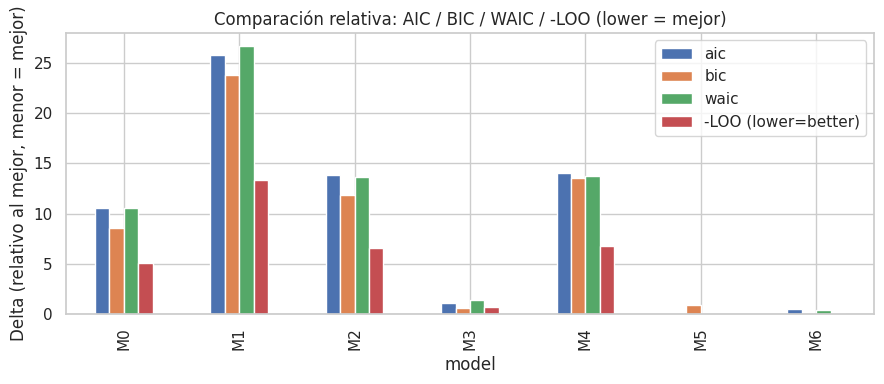


Interpretación rápida (usar en la defensa):
- Los valores son relativos: solo importan las diferencias entre modelos.
- En el plot, cada barra muestra cuánto peor está ese modelo respecto al mejor según cada criterio.
- Si AIC/BIC y WAIC/LOO coinciden en elegir un modelo, la elección es robusta.
- Si difieren, puede deberse a tamaño de muestra, estructura del prior o sobreajuste (AIC tiende a favorecer complejidad respecto a BIC).
- -LOO es la suma de log predictive densities; lo invertimos para que 'menor = mejor' y sea comparable visualmente.


In [24]:
# Comparación automática: AIC/BIC (OLS) vs WAIC / LOO-exacto (Bayes conjugado)
# - Ejecuta 3 modelos en un for, guarda métricas y plotea comparaciones relativas (delta).
# - No usa PyMC/arviz (evita incompatibilidades). Usa conjugación Normal-Inverse-Gamma.
# Requisitos: numpy, pandas, scipy, statsmodels, matplotlib, seaborn

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.stats import invgamma, t
from scipy.special import logsumexp

sns.set(style="whitegrid")
RND = 123
np.random.seed(RND)

# --- Parámetros que puedes cambiar ---
draws = 2000         # número de muestras del posterior para WAIC
prior_scale = 10.0   # sd de priors normales en coeficientes (mayor = prior más débil)

# --- Datos ---
mt = sm.datasets.get_rdataset("mtcars", "datasets").data
df_full = mt.copy().reset_index().rename(columns={'index':'car'})

# --- Modelos candidatos ---
formulas = {
    "M0": "mpg ~ wt",
    "M1": "mpg ~ hp",
    "M2": "mpg ~ cyl",
    "M3": "mpg ~ wt + hp",
    "M4": "mpg ~ hp + cyl",
    "M5": "mpg ~ wt + hp + cyl",
    "M6": "mpg ~ wt + cyl",
}

# ========== Funciones auxiliares bayesianas (conjugadas) ==========
def build_X_y(data, formula):
    y_var = formula.split("~")[0].strip()
    rhs = formula.split("~")[1].strip()
    predictors = [p.strip() for p in rhs.split("+")]
    X = data[predictors].copy()
    X = sm.add_constant(X)
    y = data[y_var].values
    return X.values, y, X.columns.tolist()

def posterior_conjugate(X, y, prior_scale=10.0, a0=2.0, d0=1.0):
    # returns bn, Vn, an, dn (analytical posterior params)
    n, p = X.shape
    XtX = X.T @ X
    Xty = X.T @ y
    V0 = (prior_scale ** 2) * np.eye(p)
    V0_inv = np.linalg.inv(V0)
    Vn_inv = XtX + V0_inv
    Vn = np.linalg.inv(Vn_inv)
    bn = Vn @ (Xty + V0_inv @ np.zeros(p))
    an = a0 + n/2.0
    yty = y.T @ y
    bn_term = bn.T @ (Vn_inv @ bn)
    dn = d0 + 0.5 * (yty - bn_term)  # since b0 = 0 term=0 -> simplified
    return {"bn": bn, "Vn": Vn, "an": an, "dn": dn}

def sample_posterior(post, draws=2000, random_state=None):
    rng = np.random.default_rng(random_state)
    bn, Vn, an, dn = post["bn"], post["Vn"], post["an"], post["dn"]
    sigma2 = invgamma.rvs(a=an, scale=dn, size=draws, random_state=rng)
    p = bn.shape[0]
    betas = np.empty((draws, p))
    for i, s2 in enumerate(sigma2):
        betas[i, :] = rng.multivariate_normal(mean=bn, cov=s2 * Vn)
    return {"beta": betas, "sigma2": sigma2}

def ll_matrix_from_samples(X, y, samples):
    # ll[s,i] = log p(y_i | beta_s, sigma2_s)
    S = samples["beta"].shape[0]
    n = len(y)
    betas = samples["beta"]
    s2 = samples["sigma2"]
    mus = betas @ X.T   # shape (S, n)
    ll = -0.5 * (np.log(2*np.pi*s2)[:, None] + ((y[None,:] - mus)**2) / s2[:, None])
    return ll  # shape (S, n)

def waic_from_ll(ll):
    S = ll.shape[0]
    lppd_i = logsumexp(ll, axis=0) - np.log(S)  # per-observation
    lppd = np.sum(lppd_i)
    p_waic = np.sum(np.var(ll, axis=0, ddof=1))
    waic = -2.0 * (lppd - p_waic)
    return float(waic), float(p_waic)

def exact_loo_analytic(formula, data, prior_scale=10.0):
    # exact LOO using analytic conjugate posterior (no MCMC)
    X_full, y_full, cols = build_X_y(data, formula)
    n = len(y_full)
    lpds = np.zeros(n)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        X_minus = X_full[mask,:]
        y_minus = y_full[mask]
        post_minus = posterior_conjugate(X_minus, y_minus, prior_scale=prior_scale)
        an = post_minus["an"]
        dn = post_minus["dn"]
        bn = post_minus["bn"]
        Vn = post_minus["Vn"]
        x_i = X_full[i,:]
        mu_pred = x_i @ bn
        scale2 = dn / an * (1.0 + x_i @ Vn @ x_i.T)
        df = 2.0 * an
        lpds[i] = t.logpdf(y_full[i], df=df, loc=mu_pred, scale=np.sqrt(scale2))
    loo_sum = np.sum(lpds)
    return float(loo_sum)   # higher = better predictive density; we'll invert for "lower is better"

# ========== Loop sobre modelos: calcular métricas ==========
results = []
for name, formula in formulas.items():
    data = df_full.copy()
    # OLS
    ols_res = smf.ols(formula=formula, data=data).fit()
    aic = float(ols_res.aic)
    bic = float(ols_res.bic)
    # Bayesian conjugate posterior and WAIC (requires sampling)
    X, y, cols = build_X_y(data, formula)
    post = posterior_conjugate(X, y, prior_scale=prior_scale)
    samples = sample_posterior(post, draws=draws, random_state=RND)
    ll = ll_matrix_from_samples(X, y, samples)  # shape (S,n)
    waic, p_waic = waic_from_ll(ll)
    # exact LOO (analytic)
    loo_sum = exact_loo_analytic(formula, data, prior_scale=prior_scale)
    # store (we invert loo_sum to get "lower is better", consistent with AIC/BIC/WAIC)
    results.append({
        "model": name,
        "formula": formula,
        "aic": aic,
        "bic": bic,
        "waic": waic,
        "p_waic": p_waic,
        "loo_sum": loo_sum,
        "neg_loo": -loo_sum  # lower is better
    })

df_res = pd.DataFrame(results).set_index("model")
display(df_res)

# ========== Plot comparativo (deltas relativos) ==========
# We'll show deltas per criterio (value - min(value) across models) so "0" = mejor
metrics = ["aic","bic","waic","neg_loo"]
delta = df_res[metrics] - df_res[metrics].min()
delta = delta.rename(columns={"neg_loo":"-LOO (lower=better)"})
delta.plot(kind="bar", figsize=(9,4))
plt.ylabel("Delta (relativo al mejor, menor = mejor)")
plt.title("Comparación relativa: AIC / BIC / WAIC / -LOO (lower = mejor)")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

# ========== Impresiones rápidas para la defensa ==========
print("\nInterpretación rápida (usar en la defensa):")
print("- Los valores son relativos: solo importan las diferencias entre modelos.")
print("- En el plot, cada barra muestra cuánto peor está ese modelo respecto al mejor según cada criterio.")
print("- Si AIC/BIC y WAIC/LOO coinciden en elegir un modelo, la elección es robusta.")
print("- Si difieren, puede deberse a tamaño de muestra, estructura del prior o sobreajuste (AIC tiende a favorecer complejidad respecto a BIC).")
print("- -LOO es la suma de log predictive densities; lo invertimos para que 'menor = mejor' y sea comparable visualmente.")


# INTERVALOS DE COFIANZA vs. INTERVALOS DE CREDIBILIDAD

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import ipywidgets as widgets
from IPython.display import display

# cargar dataset tips
tips = sns.load_dataset("tips")

def plot_intervals(n=20, prior_strength=100.0):
    np.random.seed(0)

    # tomar muestra
    data = tips["tip"].sample(n=n, replace=False)

    # estadísticas básicas
    mean = data.mean()
    std = data.std(ddof=1)
    se = std / np.sqrt(n)

    # ----------------------
    # Intervalo de Confianza
    # ----------------------
    ic_low, ic_high = stats.t.interval(
        0.95, df=n-1, loc=mean, scale=se
    )

    # ----------------------
    # Intervalo de Credibilidad
    # prior normal débil/fuerte
    # ----------------------
    prior_mean = tips["tip"].mean()   # creencia previa razonable
    prior_var = prior_strength        # controla la fuerza del prior
    lik_var = std**2 / n

    post_var = 1 / (1/prior_var + 1/lik_var)
    post_mean = post_var * (prior_mean/prior_var + mean/lik_var)

    cri_low, cri_high = stats.norm.interval(
        0.95, loc=post_mean, scale=np.sqrt(post_var)
    )

    # ----------------------
    # Forest plot
    # ----------------------
    fig, ax = plt.subplots(figsize=(8, 3))

    ax.plot([ic_low, ic_high], [1, 1], lw=4)
    ax.plot([cri_low, cri_high], [0, 0], lw=4)

    ax.scatter(mean, 1)
    ax.scatter(post_mean, 0)

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["CrI (bayesiano)", "IC (frecuentista)"])
    ax.set_xlabel("Propina promedio")
    ax.set_title(f"IC vs CrI | n = {n} | fuerza prior = {prior_strength}")

    plt.show()


# sliders interactivos
slider_n = widgets.IntSlider(
    value=20, min=5, max=200, step=5, description="n"
)

slider_prior = widgets.FloatSlider(
    value=100.0, min=0.1, max=500, step=5, description="Fuerza prior"
)

ui = widgets.VBox([slider_n, slider_prior])
out = widgets.interactive_output(
    plot_intervals, {"n": slider_n, "prior_strength": slider_prior}
)

display(ui, out)


Output()